# Experiment 3 — Sampling Methods (House Price Dataset)

**Covers:** Simple random, stratified and cluster sampling, category proportions, population/sample comparison, graph and CSV export.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** sample() → groupby().sample() → choice() + isin() → Compare → Save.

Clusters are real geographical regions: districts grouped into 1-degree latitude bands.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("housing.csv")

## 0. Population

In [2]:
N = len(df)
n = int(0.2 * N)
mean = df["median_house_value"].mean()

print("Population:", N, "Sample:", n, "Mean:", mean)

Population: 20640 Sample: 4128 Mean: 206855.81690891474


## 1. Simple random sampling

In [3]:
srs = df.sample(n=n, random_state=42)
print(srs.head())
print(df.sample(n=n, random_state=10).head())

       longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
20046    -119.01     36.06                25.0       1505.0             NaN   
3024     -119.46     35.14                30.0       2943.0             NaN   
15663    -122.44     37.80                52.0       3830.0             NaN   
20484    -118.72     34.28                17.0       3051.0             NaN   
9814     -121.93     36.62                34.0       2351.0             NaN   

       population  households  median_income  median_house_value  \
20046      1392.0       359.0         1.6812             47700.0   
3024       1565.0       584.0         2.5313             45800.0   
15663      1310.0       963.0         3.4801            500001.0   
20484      1705.0       495.0         5.7376            218600.0   
9814       1063.0       428.0         3.7250            278000.0   

      ocean_proximity  
20046          INLAND  
3024           INLAND  
15663        NEAR BAY  
20484       <1H OCEA

## 2. Stratified sampling using `ocean_proximity`

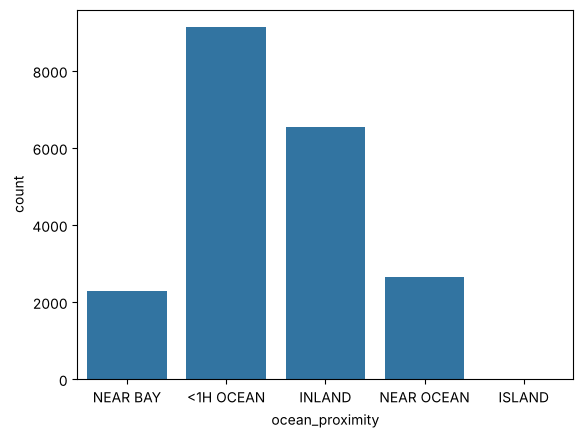

                 Population %   Sample %
ocean_proximity                         
<1H OCEAN           44.263566  44.258721
INLAND              31.739341  31.734496
NEAR OCEAN          12.877907  12.887597
NEAR BAY            11.094961  11.094961
ISLAND               0.024225   0.024225


In [4]:
sns.countplot(data=df, x="ocean_proximity")
plt.show()

strat = df.groupby("ocean_proximity", group_keys=False).sample(
    frac=0.2, random_state=42
)

print(pd.DataFrame({
    "Population %": df["ocean_proximity"].value_counts(normalize=True) * 100,
    "Sample %": strat["ocean_proximity"].value_counts(normalize=True) * 100
}))

## 3. Cluster sampling using `Region`

In [5]:
# Geographical clusters: 1-degree latitude bands
df["Region"] = df["latitude"].round().astype(int)

clusters = df["Region"].dropna().unique()
selected = np.random.default_rng(42).choice(
    clusters, size=max(1, int(0.3 * len(clusters))), replace=False
)
cluster = df[df["Region"].isin(selected)]
print("All clusters:", clusters)
print("Selected clusters:", selected)
print("Cluster sample size:", len(cluster))

All clusters: [38 37 39 40 42 36 41 33 35 34]
Selected clusters: [34 38 41]
Cluster sample size: 13534


## 4. Comparison table

In [6]:
samples = {"SRS": srs, "Stratified": strat, "Cluster": cluster}

result = pd.DataFrame({
    "Size": [len(s) for s in samples.values()],
    "Mean": [s["median_house_value"].mean() for s in samples.values()]
}, index=samples.keys())

result["Difference"] = result["Mean"] - mean
print(result)

             Size           Mean    Difference
SRS          4128  205500.309593  -1355.507316
Stratified   4128  205760.435804  -1095.381105
Cluster     13534  224572.634550  17716.817641


## 5. Graph

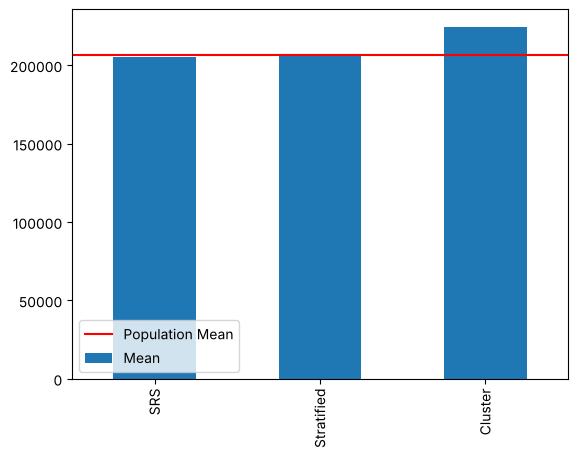

In [7]:
result["Mean"].plot(kind="bar")
plt.axhline(mean, color="red", label="Population Mean")
plt.legend()
plt.show()

## 6. Save

In [8]:
for name, sample in samples.items():
    sample.to_csv(name + ".csv", index=False)
    print("Saved", name + ".csv")

Saved SRS.csv
Saved Stratified.csv


Saved Cluster.csv


## Result / Conclusion
- Population mean house value = 206,856 (N = 20,640, sample size 4,128).
- **Stratified** sampling by `ocean_proximity` reproduces every category share almost exactly and gives the closest mean (205,760, error −1,095). **Simple random** sampling gives 205,500 (error −1,356).
- **Cluster** sampling selected 3 latitude bands (34°, 38°, 41°) with 13,534 districts; its mean is 224,573 (error +17,717) because the Los Angeles and Bay Area bands are expensive.
- Note: the first rows of the random sample show `total_bedrooms = NaN`. All 207 missing values fall in this `random_state=42` sample, apparently because the dataset's missing values were originally created with the same random seed.